# examine the predictions generated on MIMIC IV

In [11]:
import os
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
final_model_dir = "/home/jake/Documents/AI_Clinician/dynamic_deephit_results/mimic_iv/final_model"

# get the directory inside final_model_dir
inner_dir = os.listdir(final_model_dir)[0]
final_model_dir = os.path.join(final_model_dir, inner_dir)
final_model_dir


'/home/jake/Documents/AI_Clinician/dynamic_deephit_results/mimic_iv/final_model/mimic_iv_dynamic_deephit_discharge_mortality_tte_standard_20251201_180406_275977_job1208716.pbs-7'

In [3]:
# load test_set_predictions.parquet
test_set_predictions_path = Path(final_model_dir) / "test_set_predictions.parquet"
test_set_predictions = pd.read_parquet(test_set_predictions_path)
test_set_predictions.head(65)


,stay_id,event_label,time_to_event(hours),time_to_event,probs_discharge_bin0: 0h-6h,probs_discharge_bin1: 6h-12h,probs_discharge_bin2: 12h-24h,probs_discharge_bin3: 24h-48h,probs_discharge_bin4: 48h-168h,probs_discharge_bin5: 168h-336h,probs_discharge_bin6: 336h-1440h,probs_mortality_bin0: 0h-6h,probs_mortality_bin1: 6h-12h,probs_mortality_bin2: 12h-24h,probs_mortality_bin3: 24h-48h,probs_mortality_bin4: 48h-168h,probs_mortality_bin5: 168h-336h,probs_mortality_bin6: 336h-1440h
0,30000484,discharge,64,4,0.001481,0.004611,0.029901,0.224519,0.392618,0.115672,0.040234,0.002968,0.006584,0.015516,0.032635,0.066226,0.046270,0.020765
1,30000484,discharge,63,4,0.001483,0.004609,0.029843,0.224195,0.392550,0.115804,0.040283,0.002973,0.006598,0.015549,0.032693,0.066326,0.046314,0.020779
2,30000484,discharge,62,4,0.001486,0.004608,0.029784,0.223867,0.392481,0.115938,0.040332,0.002978,0.006613,0.015583,0.032752,0.066428,0.046359,0.020792
3,30000484,discharge,61,4,0.001488,0.004606,0.029724,0.223532,0.392411,0.116074,0.040383,0.002983,0.006627,0.015616,0.032811,0.066532,0.046405,0.020806
4,30000484,discharge,60,4,0.001491,0.004604,0.029662,0.223190,0.392341,0.116213,0.040436,0.002989,0.006641,0.015650,0.032871,0.066638,0.046452,0.020821
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60,30000484,discharge,4,0,0.434655,0.056511,0.254690,0.086059,0.024215,0.003287,0.000589,0.032434,0.030185,0.032594,0.027757,0.013473,0.002916,0.000635
61,30000484,discharge,3,0,0.269987,0.075340,0.350460,0.107400,0.033210,0.004871,0.000865,0.030329,0.035121,0.039746,0.033035,0.015510,0.003405,0.000722
62,30000484,discharge,2,0,0.276542,0.094493,0.333948,0.095208,0.028386,0.004362,0.000831,0.032993,0.037986,0.042099,0.033841,0.015160,0.003412,0.000737
63,30000484,discharge,1,0,0.205888,0.137544,0.351721,0.095369,0.029802,0.004678,0.000915,0.032841,0.041773,0.045133,0.035157,0.015049,0.003399,0.000730


In [9]:
# make a list of the unique time_to_event values
unique_time_to_event = test_set_predictions['time_to_event'].unique()
unique_time_to_event.sort()
unique_time_to_event

array([0, 1, 2, 3, 4, 5, 6])

In [6]:
# make a list of the discharge columns
discharge_columns = [col for col in test_set_predictions.columns if 'discharge' in col]
discharge_columns

['probs_discharge_bin0: 0h-6h',
 'probs_discharge_bin1: 6h-12h',
 'probs_discharge_bin2: 12h-24h',
 'probs_discharge_bin3: 24h-48h',
 'probs_discharge_bin4: 48h-168h',
 'probs_discharge_bin5: 168h-336h',
 'probs_discharge_bin6: 336h-1440h']

In [7]:
# make a list of the mortality columns
mortality_columns = [col for col in test_set_predictions.columns if 'mortality' in col]
mortality_columns

['probs_mortality_bin0: 0h-6h',
 'probs_mortality_bin1: 6h-12h',
 'probs_mortality_bin2: 12h-24h',
 'probs_mortality_bin3: 24h-48h',
 'probs_mortality_bin4: 48h-168h',
 'probs_mortality_bin5: 168h-336h',
 'probs_mortality_bin6: 336h-1440h']

# build heatmap for discharge

In [5]:
discharge_df = test_set_predictions[test_set_predictions['event_label'] == 'discharge']
discharge_df

,stay_id,event_label,time_to_event(hours),time_to_event,probs_discharge_bin0: 0h-6h,probs_discharge_bin1: 6h-12h,probs_discharge_bin2: 12h-24h,probs_discharge_bin3: 24h-48h,probs_discharge_bin4: 48h-168h,probs_discharge_bin5: 168h-336h,probs_discharge_bin6: 336h-1440h,probs_mortality_bin0: 0h-6h,probs_mortality_bin1: 6h-12h,probs_mortality_bin2: 12h-24h,probs_mortality_bin3: 24h-48h,probs_mortality_bin4: 48h-168h,probs_mortality_bin5: 168h-336h,probs_mortality_bin6: 336h-1440h
0,30000484,discharge,64,4,0.001481,0.004611,0.029901,0.224519,0.392618,0.115672,0.040234,0.002968,0.006584,0.015516,0.032635,0.066226,0.046270,0.020765
1,30000484,discharge,63,4,0.001483,0.004609,0.029843,0.224195,0.392550,0.115804,0.040283,0.002973,0.006598,0.015549,0.032693,0.066326,0.046314,0.020779
2,30000484,discharge,62,4,0.001486,0.004608,0.029784,0.223867,0.392481,0.115938,0.040332,0.002978,0.006613,0.015583,0.032752,0.066428,0.046359,0.020792
3,30000484,discharge,61,4,0.001488,0.004606,0.029724,0.223532,0.392411,0.116074,0.040383,0.002983,0.006627,0.015616,0.032811,0.066532,0.046405,0.020806
4,30000484,discharge,60,4,0.001491,0.004604,0.029662,0.223190,0.392341,0.116213,0.040436,0.002989,0.006641,0.015650,0.032871,0.066638,0.046452,0.020821
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1224288,39997955,discharge,5,0,0.398465,0.243795,0.090653,0.161104,0.087959,0.014154,0.002220,0.000217,0.000206,0.000194,0.000230,0.000382,0.000239,0.000181
1224289,39997955,discharge,4,0,0.336952,0.217158,0.113811,0.197585,0.109866,0.019086,0.003078,0.000348,0.000325,0.000301,0.000347,0.000554,0.000338,0.000253
1224290,39997955,discharge,3,0,0.382249,0.177532,0.131068,0.187850,0.100453,0.016511,0.002463,0.000259,0.000234,0.000225,0.000264,0.000431,0.000262,0.000198
1224291,39997955,discharge,2,0,0.334781,0.139642,0.175764,0.209510,0.114745,0.019902,0.003022,0.000348,0.000310,0.000307,0.000369,0.000621,0.000388,0.000291


In [10]:
# build an array of discharge probabilities for each unique time_to_event
discharge_probabilities = []
for time in unique_time_to_event:
    df_temp = discharge_df[discharge_df['time_to_event'] == time]
    discharge_prob = df_temp[discharge_columns].mean().values
    discharge_probabilities.append(discharge_prob)

discharge_probabilities = np.array(discharge_probabilities)
discharge_probabilities

array([[0.51062053, 0.19573028, 0.11623935, 0.08286206, 0.04225131,
        0.0087633 , 0.00240724],
       [0.3149422 , 0.2928061 , 0.16304627, 0.11135139, 0.05862301,
        0.01144051, 0.00306338],
       [0.21425503, 0.19880708, 0.26405016, 0.15973091, 0.08783302,
        0.01700694, 0.00463715],
       [0.19584598, 0.1746234 , 0.20159695, 0.18687314, 0.12556009,
        0.02985968, 0.00905939],
       [0.14009401, 0.12417033, 0.15258883, 0.182704  , 0.17250285,
        0.06385221, 0.02327126],
       [0.0796169 , 0.07357964, 0.09684024, 0.1511053 , 0.20077278,
        0.10771774, 0.04581231],
       [0.05304218, 0.04851181, 0.0698232 , 0.12155367, 0.18920866,
        0.12190874, 0.05648015]], dtype=float32)

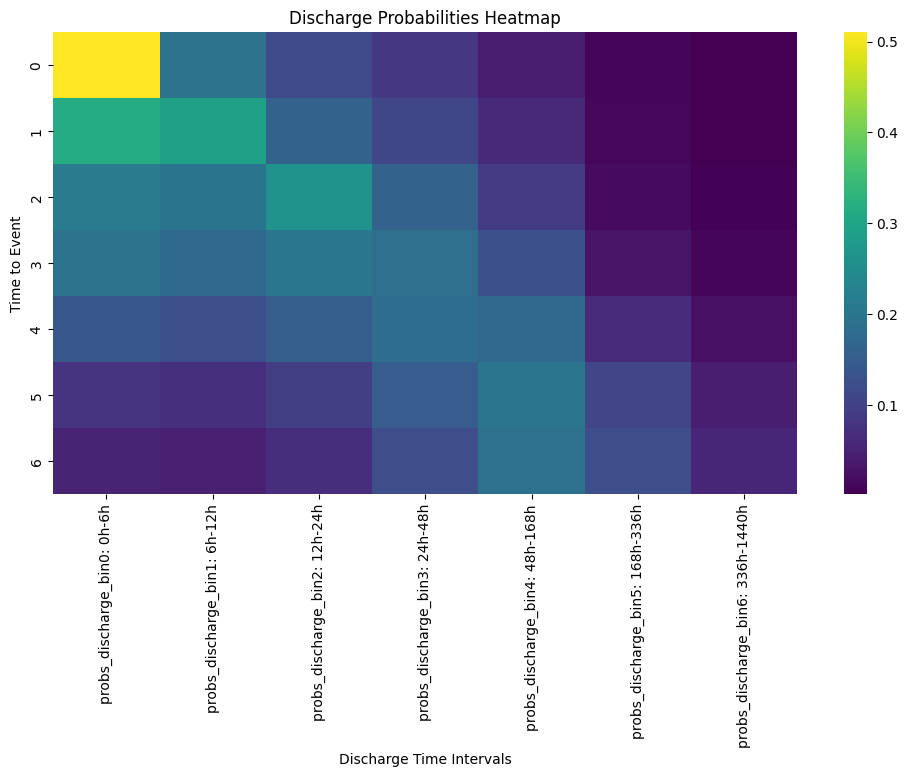

In [13]:
# plot the discharge probabilities as a heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(discharge_probabilities, xticklabels=discharge_columns, yticklabels=unique_time_to_event, cmap="viridis")
# make x labels 
plt.xlabel("Discharge Time Intervals")
plt.ylabel("Time to Event")
plt.title("Discharge Probabilities Heatmap")
plt.show()


In [15]:
mortality_df = test_set_predictions[test_set_predictions['event_label'] == 'mortality']
mortality_df

,stay_id,event_label,time_to_event(hours),time_to_event,probs_discharge_bin0: 0h-6h,probs_discharge_bin1: 6h-12h,probs_discharge_bin2: 12h-24h,probs_discharge_bin3: 24h-48h,probs_discharge_bin4: 48h-168h,probs_discharge_bin5: 168h-336h,probs_discharge_bin6: 336h-1440h,probs_mortality_bin0: 0h-6h,probs_mortality_bin1: 6h-12h,probs_mortality_bin2: 12h-24h,probs_mortality_bin3: 24h-48h,probs_mortality_bin4: 48h-168h,probs_mortality_bin5: 168h-336h,probs_mortality_bin6: 336h-1440h
683,30006983,mortality,990,6,0.017507,0.035194,0.107709,0.179002,0.115523,0.017783,0.003510,0.040254,0.092584,0.129699,0.140914,0.091913,0.022902,0.005505
684,30006983,mortality,989,6,0.018120,0.035038,0.109944,0.185595,0.114941,0.016465,0.002899,0.040157,0.089692,0.126119,0.140752,0.092177,0.022689,0.005414
685,30006983,mortality,988,6,0.010774,0.034377,0.132685,0.213481,0.139207,0.024468,0.006377,0.025327,0.072372,0.104934,0.116339,0.086117,0.026389,0.007152
686,30006983,mortality,987,6,0.014502,0.037586,0.171048,0.233636,0.120423,0.014442,0.002180,0.036202,0.070210,0.097103,0.108620,0.071794,0.017977,0.004276
687,30006983,mortality,986,6,0.008783,0.034154,0.207533,0.266448,0.131504,0.014358,0.002104,0.025301,0.054331,0.079328,0.092539,0.063438,0.016359,0.003822
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1222731,39979841,mortality,5,0,0.001320,0.002378,0.006487,0.027351,0.141639,0.118927,0.059784,0.053564,0.090092,0.121087,0.124412,0.114582,0.088673,0.049704
1222732,39979841,mortality,4,0,0.000992,0.001239,0.005367,0.025858,0.127473,0.109578,0.053519,0.033861,0.066286,0.126027,0.174995,0.146115,0.088446,0.040244
1222733,39979841,mortality,3,0,0.000576,0.000776,0.002624,0.010033,0.052423,0.050666,0.025571,0.199685,0.171410,0.186446,0.153178,0.076979,0.045348,0.024286
1222734,39979841,mortality,2,0,0.000737,0.000893,0.002885,0.011318,0.060861,0.060721,0.031098,0.133819,0.152399,0.193451,0.173636,0.094990,0.054543,0.028649


In [16]:
# build an array of mortality probabilities for each unique time_to_event
mortality_probabilities = []
for time in unique_time_to_event:
    df_temp = mortality_df[mortality_df['time_to_event'] == time]
    mortality_prob = df_temp[mortality_columns].mean().values
    mortality_probabilities.append(mortality_prob)

mortality_probabilities = np.array(mortality_probabilities)
mortality_probabilities

array([[0.29219782, 0.15851273, 0.09798972, 0.06343865, 0.03655651,
        0.0155084 , 0.00633225],
       [0.17014192, 0.16364294, 0.12171769, 0.08483215, 0.05101154,
        0.02186426, 0.00852047],
       [0.11710073, 0.13682504, 0.12207242, 0.09642546, 0.06250947,
        0.02718635, 0.01026441],
       [0.08758344, 0.11003865, 0.11047984, 0.1015035 , 0.07335822,
        0.03324356, 0.01227601],
       [0.06431285, 0.0887813 , 0.10034703, 0.1066541 , 0.08715851,
        0.04215245, 0.01548863],
       [0.0582388 , 0.0826271 , 0.09571464, 0.10648368, 0.0932477 ,
        0.04766219, 0.01834203],
       [0.05688192, 0.08532471, 0.10112703, 0.11461612, 0.10316472,
        0.05430118, 0.02173915]], dtype=float32)

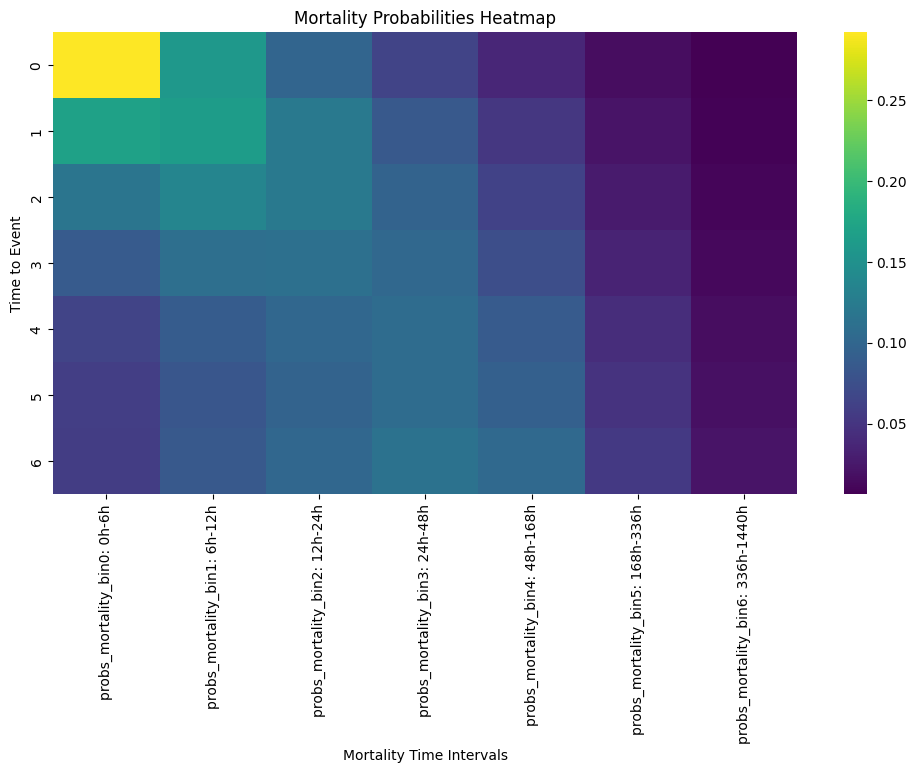

In [17]:
# plot the discharge probabilities as a heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(mortality_probabilities, xticklabels=mortality_columns, yticklabels=unique_time_to_event, cmap="viridis")
# make x labels 
plt.xlabel("Mortality Time Intervals")
plt.ylabel("Time to Event")
plt.title("Mortality Probabilities Heatmap")
plt.show()